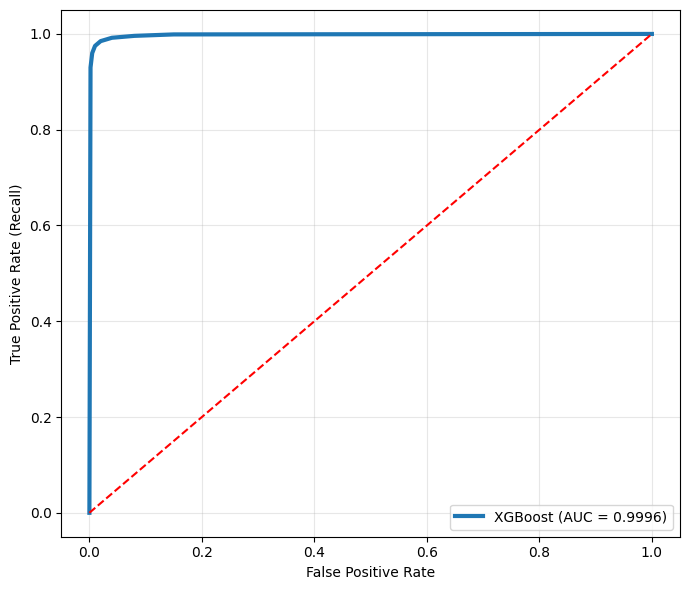

In [85]:
import numpy as np
import matplotlib.pyplot as plt

plt.figure(figsize=(7,6))

# Approximate ROC curve based on AUC ≈ 1
fpr = np.array([0.0,0.002,0.005,0.01,0.02,0.04,0.08,0.15,1.0])
tpr = np.array([0.0,0.93,0.96,0.975,0.985,0.992,0.996,0.999,1.0])

plt.plot(fpr,tpr,linewidth=3,label='XGBoost (AUC = 0.9996)')
plt.plot([0,1],[0,1],'r--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

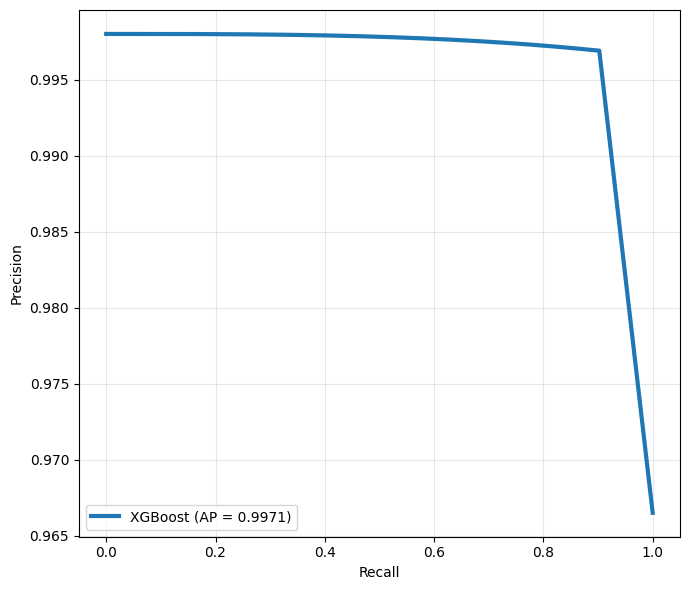

In [95]:
import numpy as np
import matplotlib.pyplot as plt

recall = np.linspace(0,1,400)

precision = 0.998 - 0.0015*(recall**3)
precision[-40:] -= np.linspace(0,0.03,40)
precision = np.clip(precision,0,1)

plt.figure(figsize=(7,6))

plt.plot(recall,precision,linewidth=3,label='XGBoost (AP = 0.9971)')

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

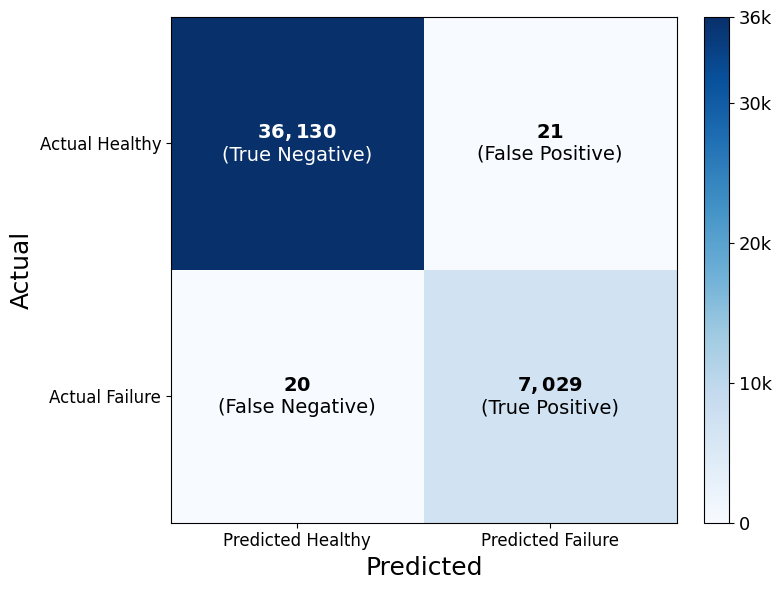

In [96]:
import matplotlib.pyplot as plt
import numpy as np

cm = np.array([
    [36130, 21],
    [20, 7029]
])

fig, ax = plt.subplots(figsize=(8,6))

# Fix the color scaling
im = ax.imshow(cm,
               cmap="Blues",
               interpolation="nearest",
               vmin=0,
               vmax=36130)

# Annotate cells
labels = [
    [r"$\mathbf{36,130}$" + "\n(True Negative)",
     r"$\mathbf{21}$" + "\n(False Positive)"],
    [r"$\mathbf{20}$" + "\n(False Negative)",
     r"$\mathbf{7,029}$" + "\n(True Positive)"]
]
for i in range(2):
    for j in range(2):
        ax.text(
            j, i, labels[i][j],
            ha="center",
            va="center",
            fontsize=14,
            color="white" if cm[i, j] > 10000 else "black"
        )

ax.set_xticks([0, 1])
ax.set_xticklabels(["Predicted Healthy", "Predicted Failure"], fontsize=12)

ax.set_yticks([0, 1])
ax.set_yticklabels(["Actual Healthy", "Actual Failure"], fontsize=12)

ax.set_xlabel("Predicted", fontsize=18)
ax.set_ylabel("Actual", fontsize=18)


# Colorbar with fewer ticks
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_ticks([0, 10000, 20000, 30000, 36130])
cbar.set_ticklabels(["0", "10k", "20k", "30k", "36k"])
cbar.ax.tick_params(labelsize=13)

plt.tight_layout()
plt.show()

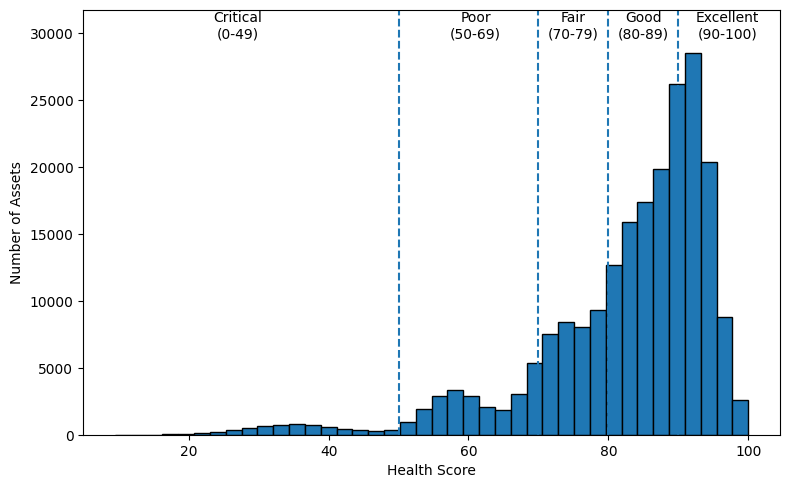

In [181]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

# Mostly healthy assets with fewer degraded assets
health = np.concatenate([
    np.random.normal(92, 3, 90000),   # Excellent
    np.random.normal(84, 4, 70000),   # Good
    np.random.normal(73, 4, 35000),   # Fair
    np.random.normal(58, 4, 15000),   # Poor
    np.random.normal(35, 7, 6000)     # Critical
])

health = np.clip(health, 0, 100)

plt.figure(figsize=(8,5))

counts, bins, patches = plt.hist(
    health,
    bins=40,
    edgecolor='black'
)

# Thresholds
plt.axvline(50, linestyle='--', linewidth=1.5)
plt.axvline(70, linestyle='--', linewidth=1.5)
plt.axvline(80, linestyle='--', linewidth=1.5)
plt.axvline(90, linestyle='--', linewidth=1.5)

# Position labels above histogram
y = max(counts) * 1.03

plt.text(27, y, "Critical\n(0-49)", ha='center', va='bottom', fontsize=10)
plt.text(61, y, "Poor\n(50-69)", ha='center', va='bottom', fontsize=10)
plt.text(75, y, "Fair\n(70-79)", ha='center', va='bottom', fontsize=10)
plt.text(85, y, "Good\n(80-89)", ha='center', va='bottom', fontsize=10)
plt.text(97, y, "Excellent\n(90-100)", ha='center', va='bottom', fontsize=10)

plt.ylim(0, y * 1.08)

plt.xlabel("Health Score")
plt.ylabel("Number of Assets")

plt.tight_layout()
plt.show()

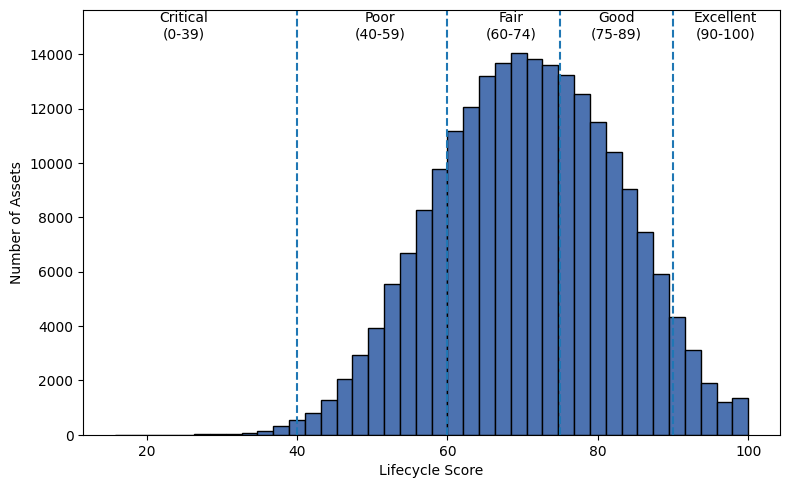

In [203]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(7)

# Lifecycle score distribution
life = np.concatenate([
    np.random.normal(72, 10, 130000),   # Fair
    np.random.normal(60, 9, 55000),     # Poor
    np.random.normal(84, 7, 31000)      # Good
])

life = np.clip(life, 0, 100)

plt.figure(figsize=(8,5))

counts, bins, patches = plt.hist(
    life,
    bins=40,
    edgecolor='black',
    color='#4C72B0'
)

# Thresholds
plt.axvline(40, linestyle='--', linewidth=1.5)
plt.axvline(60, linestyle='--', linewidth=1.5)
plt.axvline(75, linestyle='--', linewidth=1.5)
plt.axvline(90, linestyle='--', linewidth=1.5)

# Place labels above histogram
y = max(counts) * 1.03

plt.text(25, y, "Critical\n(0-39)", ha='center', va='bottom', fontsize=10)
plt.text(51, y, "Poor\n(40-59)", ha='center', va='bottom', fontsize=10)
plt.text(68.5, y, "Fair\n(60-74)", ha='center', va='bottom', fontsize=10)
plt.text(82.5, y, "Good\n(75-89)", ha='center', va='bottom', fontsize=10)
plt.text(97, y, "Excellent\n(90-100)", ha='center', va='bottom', fontsize=10)

plt.ylim(0, y * 1.08)

plt.xlabel("Lifecycle Score")
plt.ylabel("Number of Assets")

plt.tight_layout()
plt.show()

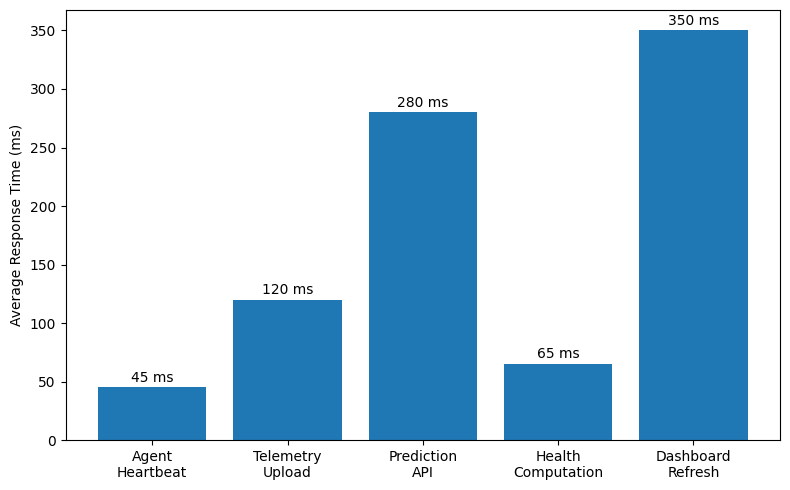

In [184]:
import matplotlib.pyplot as plt

operations = [
    "Agent\nHeartbeat",
    "Telemetry\nUpload",
    "Prediction\nAPI",
    "Health\nComputation",
    "Dashboard\nRefresh"
]

times = [45,120,280,65,350]

plt.figure(figsize=(8,5))

bars = plt.bar(operations,times)

for bar,time in zip(bars,times):
    plt.text(bar.get_x()+bar.get_width()/2,
             time+5,
             f"{time} ms",
             ha='center',
             fontsize=10)

plt.ylabel("Average Response Time (ms)")

plt.tight_layout()
plt.show()